# Proyecto Integrador de Ciencia de Datos e Inteligencia Artificial
## Fase 3: Modelado Avanzado, Clustering, Optimización e Interpretabilidad (Entregable 3 - 25%)

* **Estudiante:** Yerson León Montañez
* **Correo Institucional:** `yeleon36@unisalle.edu.co`
* **Institución:** Universidad de La Salle — Facultad de Ingeniería / Maestría en Inteligencia Artificial
* **Asignatura:** Ciencia de Datos
* **Docente:** Fabián Camilo Castro Riveros
* **Periodo Académico:** 20 de octubre – 28 de noviembre de 2026
* **Fecha de Entrega:** Domingo 22 de Noviembre de 2026

---
### Objetivos Técnicos de la Fase 3 (Según Guía Oficial y Rúbrica)
1. **Modelos de Regresión Continua Regularizada y Ensambles:**
   * Implementación de **Ridge ($L_2$)** y **Lasso ($L_1$)** con optimización de hiperparámetros ($lpha$) mediante Validación Cruzada (*Cross-Validation*).
   * Implementación y comparación de **Random Forest Regressor** y **XGBoost Regressor** para capturar no linealidades complejas, evaluados mediante $R^2$, RMSE y MAE.
2. **Modelos de Clasificación Supervisada y Red Neuronal:**
   * Comparación de clasificadores no lineales avanzados: **Random Forest** y **XGBoost Classifier** calibrados ante desbalance.
   * Diseño, entrenamiento y evaluación de una red neuronal profunda tipo **Perceptrón Multicapa (MLP) en PyTorch**, graficando su función de pérdida de entrenamiento y validación por época.
   * Evaluación mediante vector completo de métricas: Accuracy, Precision, Recall, $F_1\text{-score}$ (Positiva y Macro), $AUC\text{-}ROC$ y $PR\text{-}AUC$.
3. **Aprendizaje No Supervisado (Clustering / Segmentación):**
   * **K-Means Clustering:** Determinación explícita del número óptimo de clústeres ($K$) evaluando simultáneamente el **Método del Codo (Inercia WCSS)** y el **Coeficiente de Silueta**.
   * Segundo algoritmo no supervisado: **Clustering Jerárquico Aglomerativo (Ward)**.
   * Análisis profiláctico y perfilamiento de negocio de los segmentos descubiertos.
4. **Interpretabilidad Explicable (XAI):**
   * Análisis de explicabilidad global mediante **valores SHAP** (*SHapley Additive exPlanations*) sobre el modelo de gradiente impulsado XGBoost.


---
## 1. Configuración del Entorno y Carga de Módulos
Importación de librerías científicas, PyTorch, XGBoost, SHAP y utilidades modulares de `src/`.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import xgboost as xgb
import shap

# Configuración de ruta al paquete modular
sys.path.append(os.path.abspath('..'))
from src.fase2_pipeline import (
    load_and_audit_raw_data,
    preprocess_dataframe_binary_cols,
    DomainFeatureEngineer,
    split_dataset_stratified,
    build_feature_preprocessor
)
from src.fase3_models import (
    build_regression_feature_preprocessor,
    train_and_evaluate_regression_advanced,
    train_and_evaluate_classification_advanced,
    analyze_clustering_unsupervised,
    compute_shap_explanations,
    generate_fase3_figures,
    set_seed
)

set_seed(42)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 140
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# Localización de datos
DATA_PATH = os.path.join('..', 'data', 'raw', 'telco_customer_churn.csv')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'raw', 'telco_customer_churn.csv')

print(f"[OK] Entorno configurado con PyTorch {torch.__version__}, XGBoost {xgb.__version__} y SHAP {shap.__version__}.")


C:\Users\yelem\AppData\Roaming\Python\Python312\site-packages\torch\utils\_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(


C:\Users\yelem\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[OK] Entorno configurado con PyTorch 2.6.0+cu124, XGBoost 3.4.1 y SHAP 0.54.1.


---
## 2. Preparación de Matrices Sin Fuga de Información (*Data Leakage Prevention*)

Se aplican las transformaciones y variables derivadas establecidas en la Fase 2:
1. **Regresión:** Se excluye `TotalCharges_Clean` y sus derivadas para prevenir **Target Leakage**.
2. **Clasificación:** Se utiliza la matriz estandarizada completa para predecir `Churn`.
3. **División:** Train (70%), Validación (15%) y Prueba (15%) estratificados.


In [2]:
df_raw, missing = load_and_audit_raw_data(DATA_PATH)
engineer = DomainFeatureEngineer()
df_featured = engineer.transform(preprocess_dataframe_binary_cols(df_raw))

splits = split_dataset_stratified(df_raw, target_col='Churn', test_size=0.15, val_size=0.15, random_state=42)

X_tr_feat = engineer.transform(preprocess_dataframe_binary_cols(splits['X_train']))
X_va_feat = engineer.transform(preprocess_dataframe_binary_cols(splits['X_val']))
X_te_feat = engineer.transform(preprocess_dataframe_binary_cols(splits['X_test']))

# 1. Pipeline de Regresión
reg_preprocessor = build_regression_feature_preprocessor(scaler_type='standard')
X_tr_reg_proc = reg_preprocessor.fit_transform(X_tr_feat)
X_va_reg_proc = reg_preprocessor.transform(X_va_feat)
X_te_reg_proc = reg_preprocessor.transform(X_te_feat)

y_tr_reg = splits['X_train']['TotalCharges_Clean'].values
y_va_reg = splits['X_val']['TotalCharges_Clean'].values
y_te_reg = splits['X_test']['TotalCharges_Clean'].values

# 2. Pipeline de Clasificación
clf_preprocessor = build_feature_preprocessor(scaler_type='standard')
X_tr_clf_proc = clf_preprocessor.fit_transform(X_tr_feat)
X_va_clf_proc = clf_preprocessor.transform(X_va_feat)
X_te_clf_proc = clf_preprocessor.transform(X_te_feat)

nom_cols = clf_preprocessor.named_transformers_['nom'].get_feature_names_out().tolist()
feature_names = (
    ['tenure', 'MonthlyCharges', 'TotalCharges_Clean', 'TotalServices', 'AvgHistoricalFee', 'FeeDiscrepancyRatio'] +
    ['Contract_Ordinal'] +
    nom_cols +
    ['SeniorCitizen', 'Partner_Binary', 'Dependents_Binary', 'PhoneService_Binary', 
     'PaperlessBilling_Binary', 'AutomaticPayment', 'LongTermContract']
)

print(f"Dimensiones Regresión - Train: {X_tr_reg_proc.shape}, Val: {X_va_reg_proc.shape}, Test: {X_te_reg_proc.shape}")
print(f"Dimensiones Clasificación - Train: {X_tr_clf_proc.shape}, Val: {X_va_clf_proc.shape}, Test: {X_te_clf_proc.shape}")


Dimensiones Regresión - Train: (4929, 31), Val: (1057, 31), Test: (1057, 31)
Dimensiones Clasificación - Train: (4929, 34), Val: (1057, 34), Test: (1057, 34)


---
## 3. Modelos de Regresión Continua Regularizada y Ensambles (`TotalCharges`)

Se evalúan cuatro familias algorítmicas para la predicción de cobros acumulados:
1. **Ridge Regression ($L_2$):** Penaliza la norma euclidiana de los coeficientes: $\min_{\beta} \|y - X\beta\|_2^2 + \alpha \|\beta\|_2^2$.
2. **Lasso Regression ($L_1$):** Penaliza el valor absoluto, induciendo dispersión: $\min_{\beta} \|y - X\beta\|_2^2 + \alpha \|\beta\|_1$.
3. **Random Forest Regressor:** Ensamble de 120 árboles con agregación de varianza (*bagging*).
4. **XGBoost Regressor:** Árboles de decisión secuenciales optimizados por gradiente con regularización estocástica.


In [3]:
reg_payload, reg_metrics = train_and_evaluate_regression_advanced(
    X_tr_reg_proc, y_tr_reg,
    X_va_reg_proc, y_va_reg,
    X_te_reg_proc, y_te_reg
)

print(f"Mejor alpha Ridge: {reg_payload['best_ridge_alpha']}")
print(f"Mejor alpha Lasso: {reg_payload['best_lasso_alpha']}")
print("\nTabla Comparativa de Métricas de Regresión:")
reg_metrics


Mejor alpha Ridge: 1.0
Mejor alpha Lasso: 0.1

Tabla Comparativa de Métricas de Regresión:


,Modelo,Split,R2 Score,RMSE (USD),MAE (USD)
0,Ridge Regression (L2),Val,0.9088,682.2838,550.5632
1,Ridge Regression (L2),Test,0.9057,681.3723,539.5025
2,Lasso Regression (L1),Val,0.9088,682.1670,550.4662
3,Lasso Regression (L1),Test,0.9058,681.2978,539.4534
4,Random Forest Regressor,Val,0.9986,83.2731,56.1890
5,Random Forest Regressor,Test,0.9986,81.9051,55.8773
6,XGBoost Regressor,Val,0.9982,96.4286,68.8729
7,XGBoost Regressor,Test,0.9980,99.2398,71.8615


---
## 4. Modelos de Clasificación Supervisada y Red Neuronal en PyTorch

Se contrastan tres arquitecturas avanzadas frente al problema de deserción (`Churn`):
1. **Random Forest Classifier (Balanced):** Ensamble con ponderación de clases inversa.
2. **XGBoost Classifier:** Gradiente impulsado con `scale_pos_weight = 2.77` para contrarrestar el desbalance.
3. **Perceptrón Multicapa (MLP) en PyTorch:**
   * Arquitectura: $\text{Input}(31) \to \text{Linear}(64) \to \text{LayerNorm} \to \text{ReLU} \to \text{Dropout}(0.25) \to \text{Linear}(32) \to \text{ReLU} \to \text{Dropout}(0.25) \to \text{Linear}(1)$.
   * Función de Pérdida: `BCEWithLogitsLoss(pos_weight=2.77)`.
   * Optimizador: `Adam(lr=0.002, weight_decay=1e-4)`.


In [4]:
clf_payload, clf_metrics = train_and_evaluate_classification_advanced(
    X_tr_clf_proc, splits['y_train'].values,
    X_va_clf_proc, splits['y_val'].values,
    X_te_clf_proc, splits['y_test'].values,
    feature_names
)

print("Tabla Comparativa de Métricas de Clasificación en Validación y Prueba:")
clf_metrics


Tabla Comparativa de Métricas de Clasificación en Validación y Prueba:


,Modelo,Split,Accuracy,Precision,Recall,F1-Score (Pos),F1-Score (Macro),AUC-ROC,PR-AUC
0,Random Forest (Balanced),Val,0.7398,0.5071,0.7580,0.6077,0.7065,0.8282,0.6188
1,Random Forest (Balanced),Test,0.7512,0.5195,0.8071,0.6322,0.7221,0.8456,0.6511
2,XGBoost Classifier,Val,0.7493,0.5196,0.7544,0.6154,0.7147,0.8304,0.6272
3,XGBoost Classifier,Test,0.7474,0.5150,0.7964,0.6255,0.7175,0.8460,0.6550
4,PyTorch MLP,Val,0.7474,0.5166,0.7758,0.6202,0.7155,0.8212,0.6132
5,PyTorch MLP,Test,0.7323,0.4966,0.7857,0.6086,0.7026,0.8331,0.6424


---
## 5. Modelos de Aprendizaje No Supervisado (Clustering y Segmentación)

### 5.1. K-Means: Método del Codo y Coeficiente de Silueta
Evaluación sistemática de $K \in [2, 8]$ sobre las variables cuantitativas de comportamiento:
* `tenure`, `MonthlyCharges`, `TotalCharges_Clean`, `TotalServices`, `FeeDiscrepancyRatio`.


In [5]:
clust_payload, profile_df = analyze_clustering_unsupervised(df_featured)

k_eval_df = pd.DataFrame({
    'K': clust_payload['k_range'],
    'Inercia (WCSS)': clust_payload['inertias'],
    'Coeficiente Silueta': clust_payload['silhouette_scores']
})
print("Evaluación de Inercia y Silueta según K:")
print(k_eval_df)
print(f"\nCoeficiente de Silueta para Clustering Jerárquico Aglomerativo (Ward): {clust_payload['sil_hierarchical']:.4f}")


C:\Users\yelem\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\yelem\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1538, in

Evaluación de Inercia y Silueta según K:
   K  Inercia (WCSS)  Coeficiente Silueta
0  2      20013.5591               0.3835
1  3      15301.3738               0.3373
2  4      12743.0957               0.3419
3  5      10741.2566               0.3357
4  6       9342.3925               0.3005
5  7       8282.7591               0.2996
6  8       7519.8783               0.2978

Coeficiente de Silueta para Clustering Jerárquico Aglomerativo (Ward): 0.2682


### 5.2. Perfilamiento e Interpretación Profiláctica de Clústeres (Negocio)
Caracterización media de los tres segmentos descubiertos:


In [6]:
print("Perfiles Promedio de los Segmentos Descubiertos por K-Means (K=3):")
profile_df


Perfiles Promedio de los Segmentos Descubiertos por K-Means (K=3):


,KMeans_Cluster,Clientes,Tenure_Promedio,MonthlyCharges_Promedio,TotalCharges_Promedio,TotalServices_Promedio,FeeDiscrepancy_Promedio,Tasa_Desercion_Churn,Adopcion_PagoAuto,Contrato_LargoPlazo
0,0,2185,58.4636,90.0685,5252.4051,6.5908,0.9997,15.0114,62.5172,74.4622
1,1,2714,15.1544,74.9352,1131.3447,4.2237,1.0027,45.3574,30.5822,14.9226
2,2,2144,27.5737,26.0927,703.9150,1.5569,1.0045,14.4590,40.5784,52.9851


---
## 6. Interpretabilidad Explicable con Valores SHAP (*SHapley Additive exPlanations*)

Se calculan los valores SHAP sobre el modelo XGBoost Classifier para descomponer la contribución marginal de cada variable en la probabilidad individual de deserción:


In [7]:
shap_vals, explainer = compute_shap_explanations(
    clf_payload['xgb_clf'],
    X_te_clf_proc,
    feature_names
)

print(f"[OK] Valores SHAP calculados sobre el conjunto de prueba ({shap_vals.shape[0]} instancias, {shap_vals.shape[1]} atributos).")


[OK] Valores SHAP calculados sobre el conjunto de prueba (1057 instancias, 34 atributos).


---
## 7. Galería de Figuras Diagnósticas de la Fase 3

A continuación se generan y visualizan las figuras de alta resolución guardadas en `reports/fase3/figures/`.


In [8]:
OUTPUT_FIG_DIR = os.path.join('..', 'reports', 'fase3', 'figures')
if not os.path.exists(OUTPUT_FIG_DIR):
    OUTPUT_FIG_DIR = os.path.join('reports', 'fase3', 'figures')

generate_fase3_figures(reg_payload, clf_payload, clust_payload, shap_vals, output_dir=OUTPUT_FIG_DIR)


C:\Users\yelem\workspace\la_salle_tareas\ciencia_datos\proyecto_general\src\fase3_models.py:597: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


[OK] 6 figuras analíticas de Fase 3 guardadas exitosamente en 'reports\fase3\figures'.


### 7.1. Figura 1: Evaluación Comparativa de Modelos de Regresión ($R^2$ y RMSE)
Contraste entre modelos lineales penalizados (Ridge/Lasso) y ensambles basados en árboles (Random Forest y XGBoost).


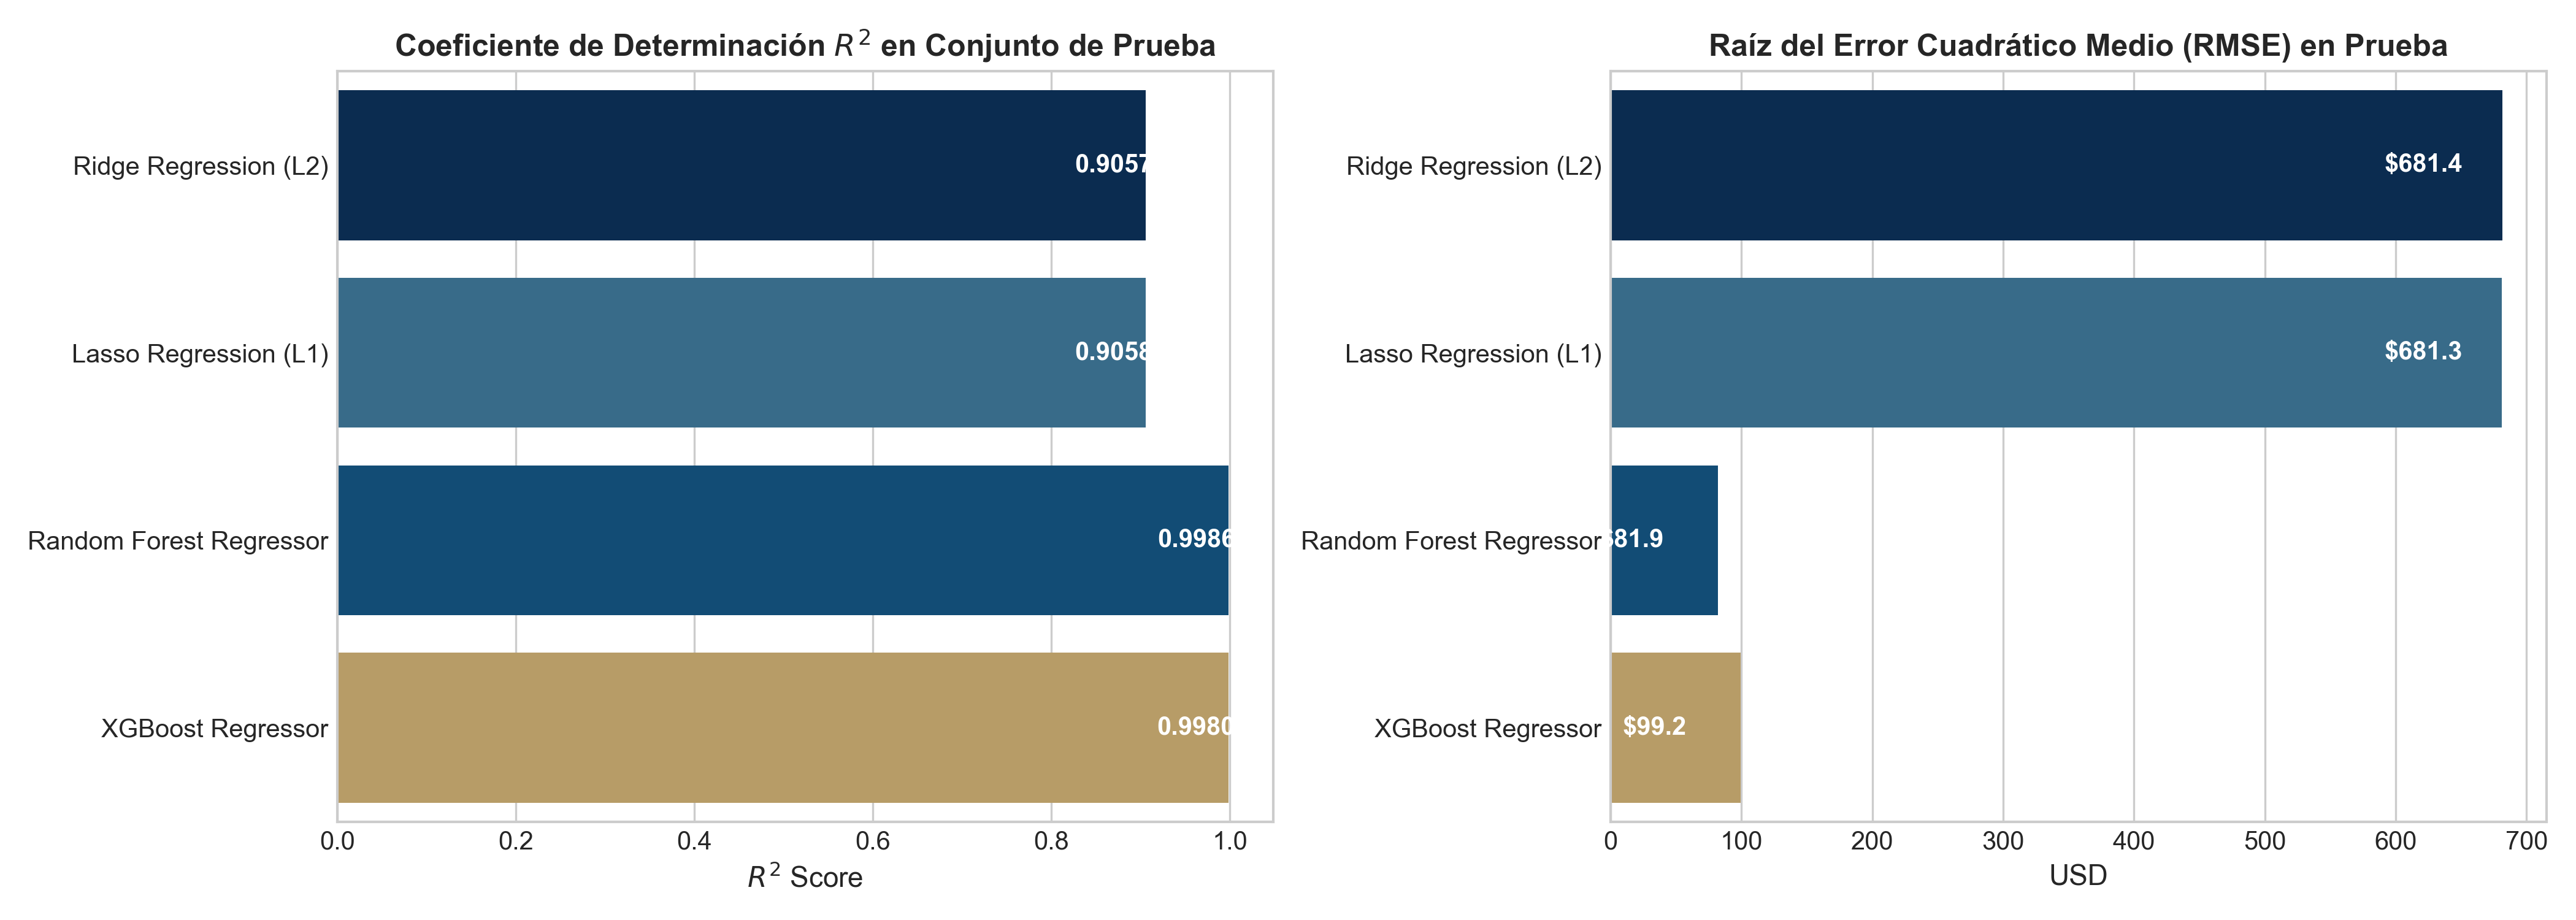

In [9]:
from IPython.display import Image, display
display(Image(filename=os.path.join(OUTPUT_FIG_DIR, 'fig1_regression_comparison.png'), width=900))


### 7.2. Figura 2: Curvas ROC y Precision-Recall en Clasificación
Capacidad discriminatoria de Random Forest, XGBoost y PyTorch MLP sobre el conjunto de prueba.


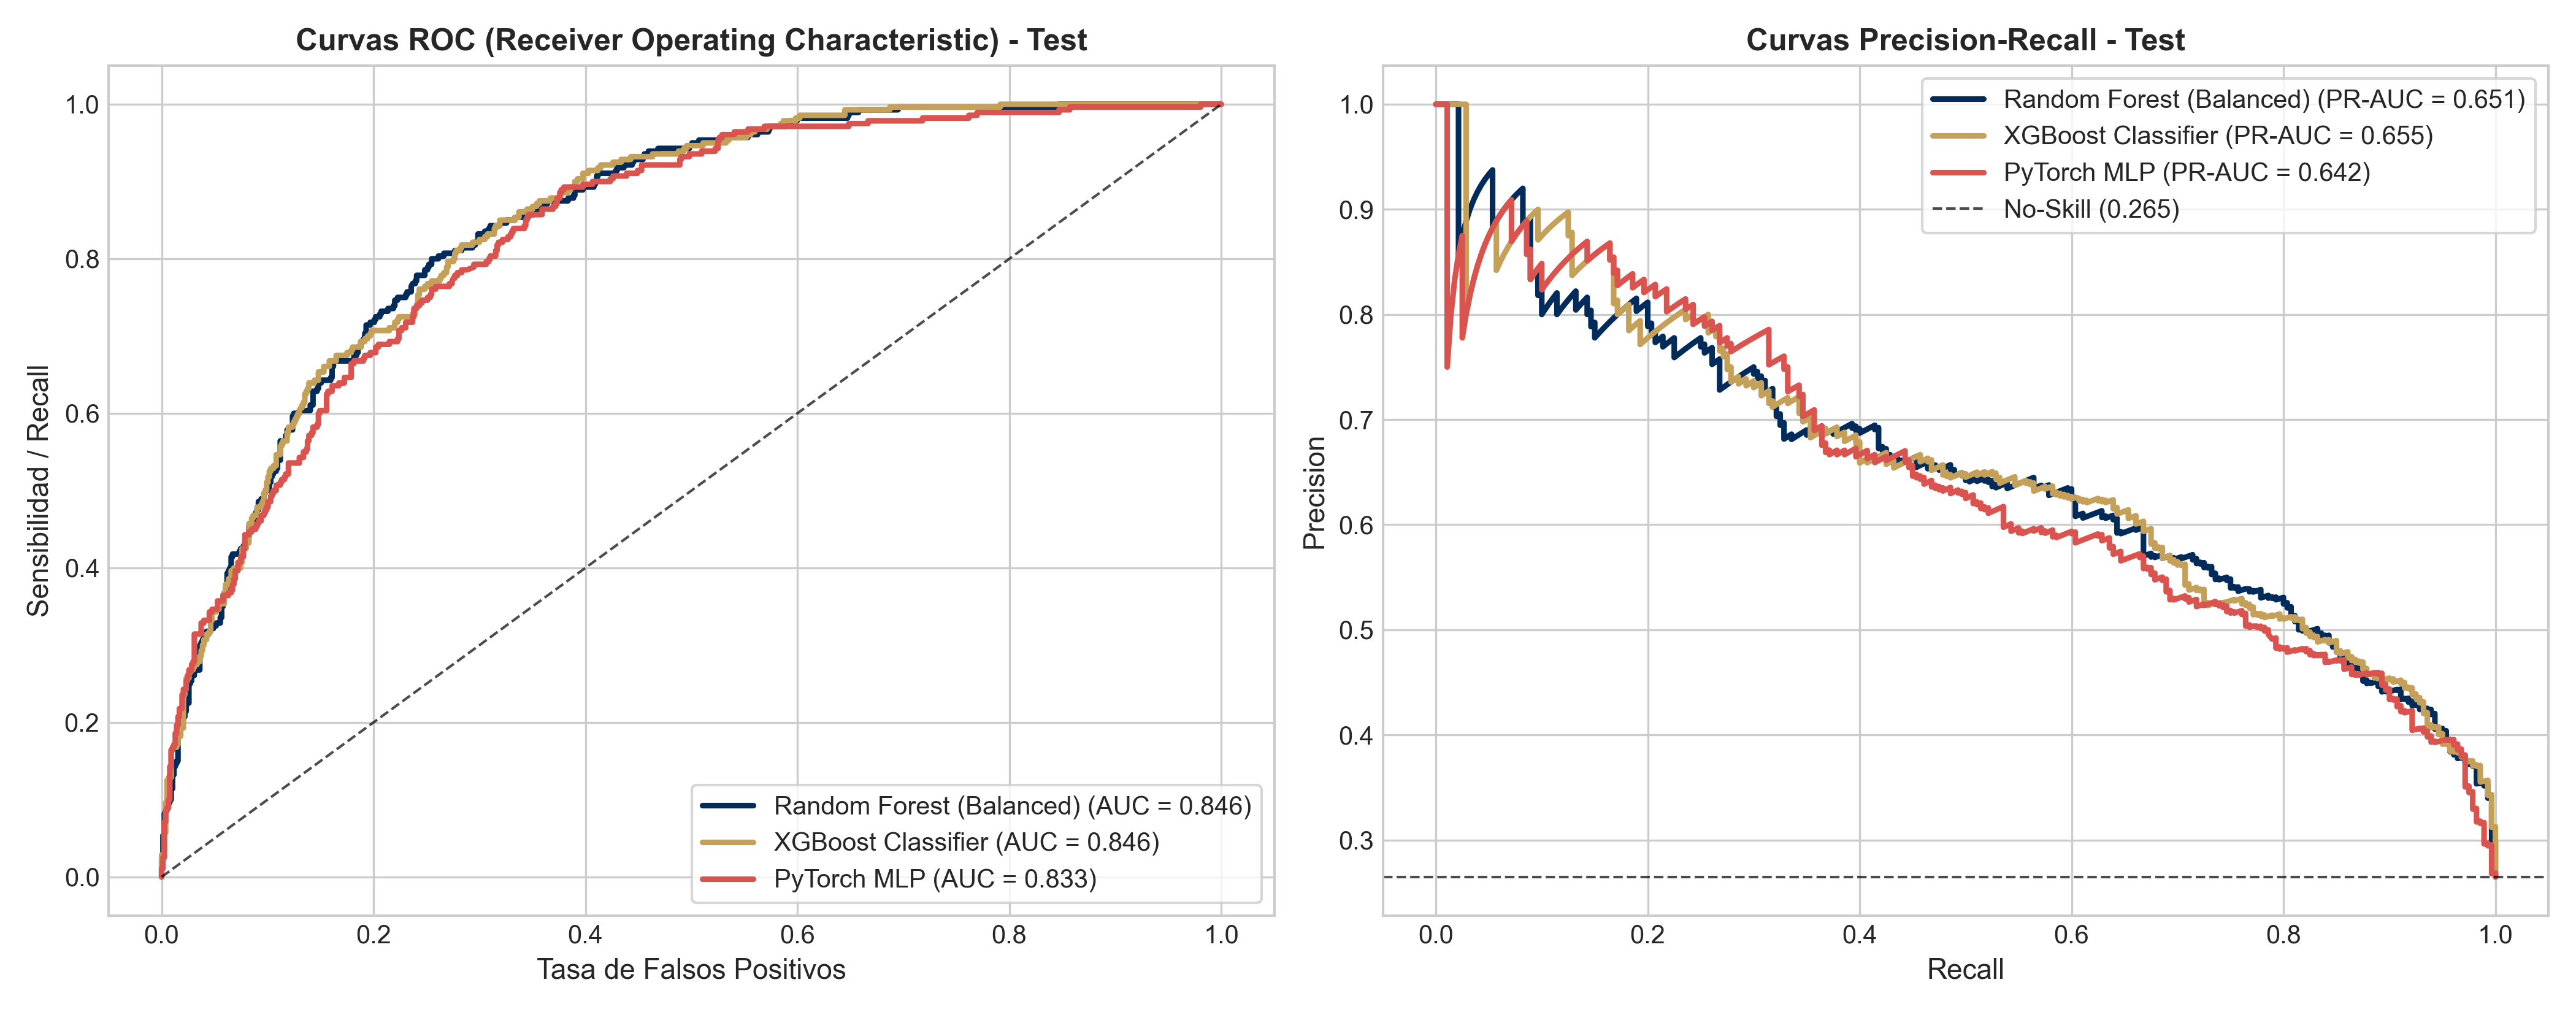

In [10]:
display(Image(filename=os.path.join(OUTPUT_FIG_DIR, 'fig2_classification_roc_pr.png'), width=900))


### 7.3. Figura 3: Curva de Convergencia de Pérdida en PyTorch MLP
Evolución de la pérdida de entrenamiento y validación a lo largo de 50 épocas sin sobreajuste.


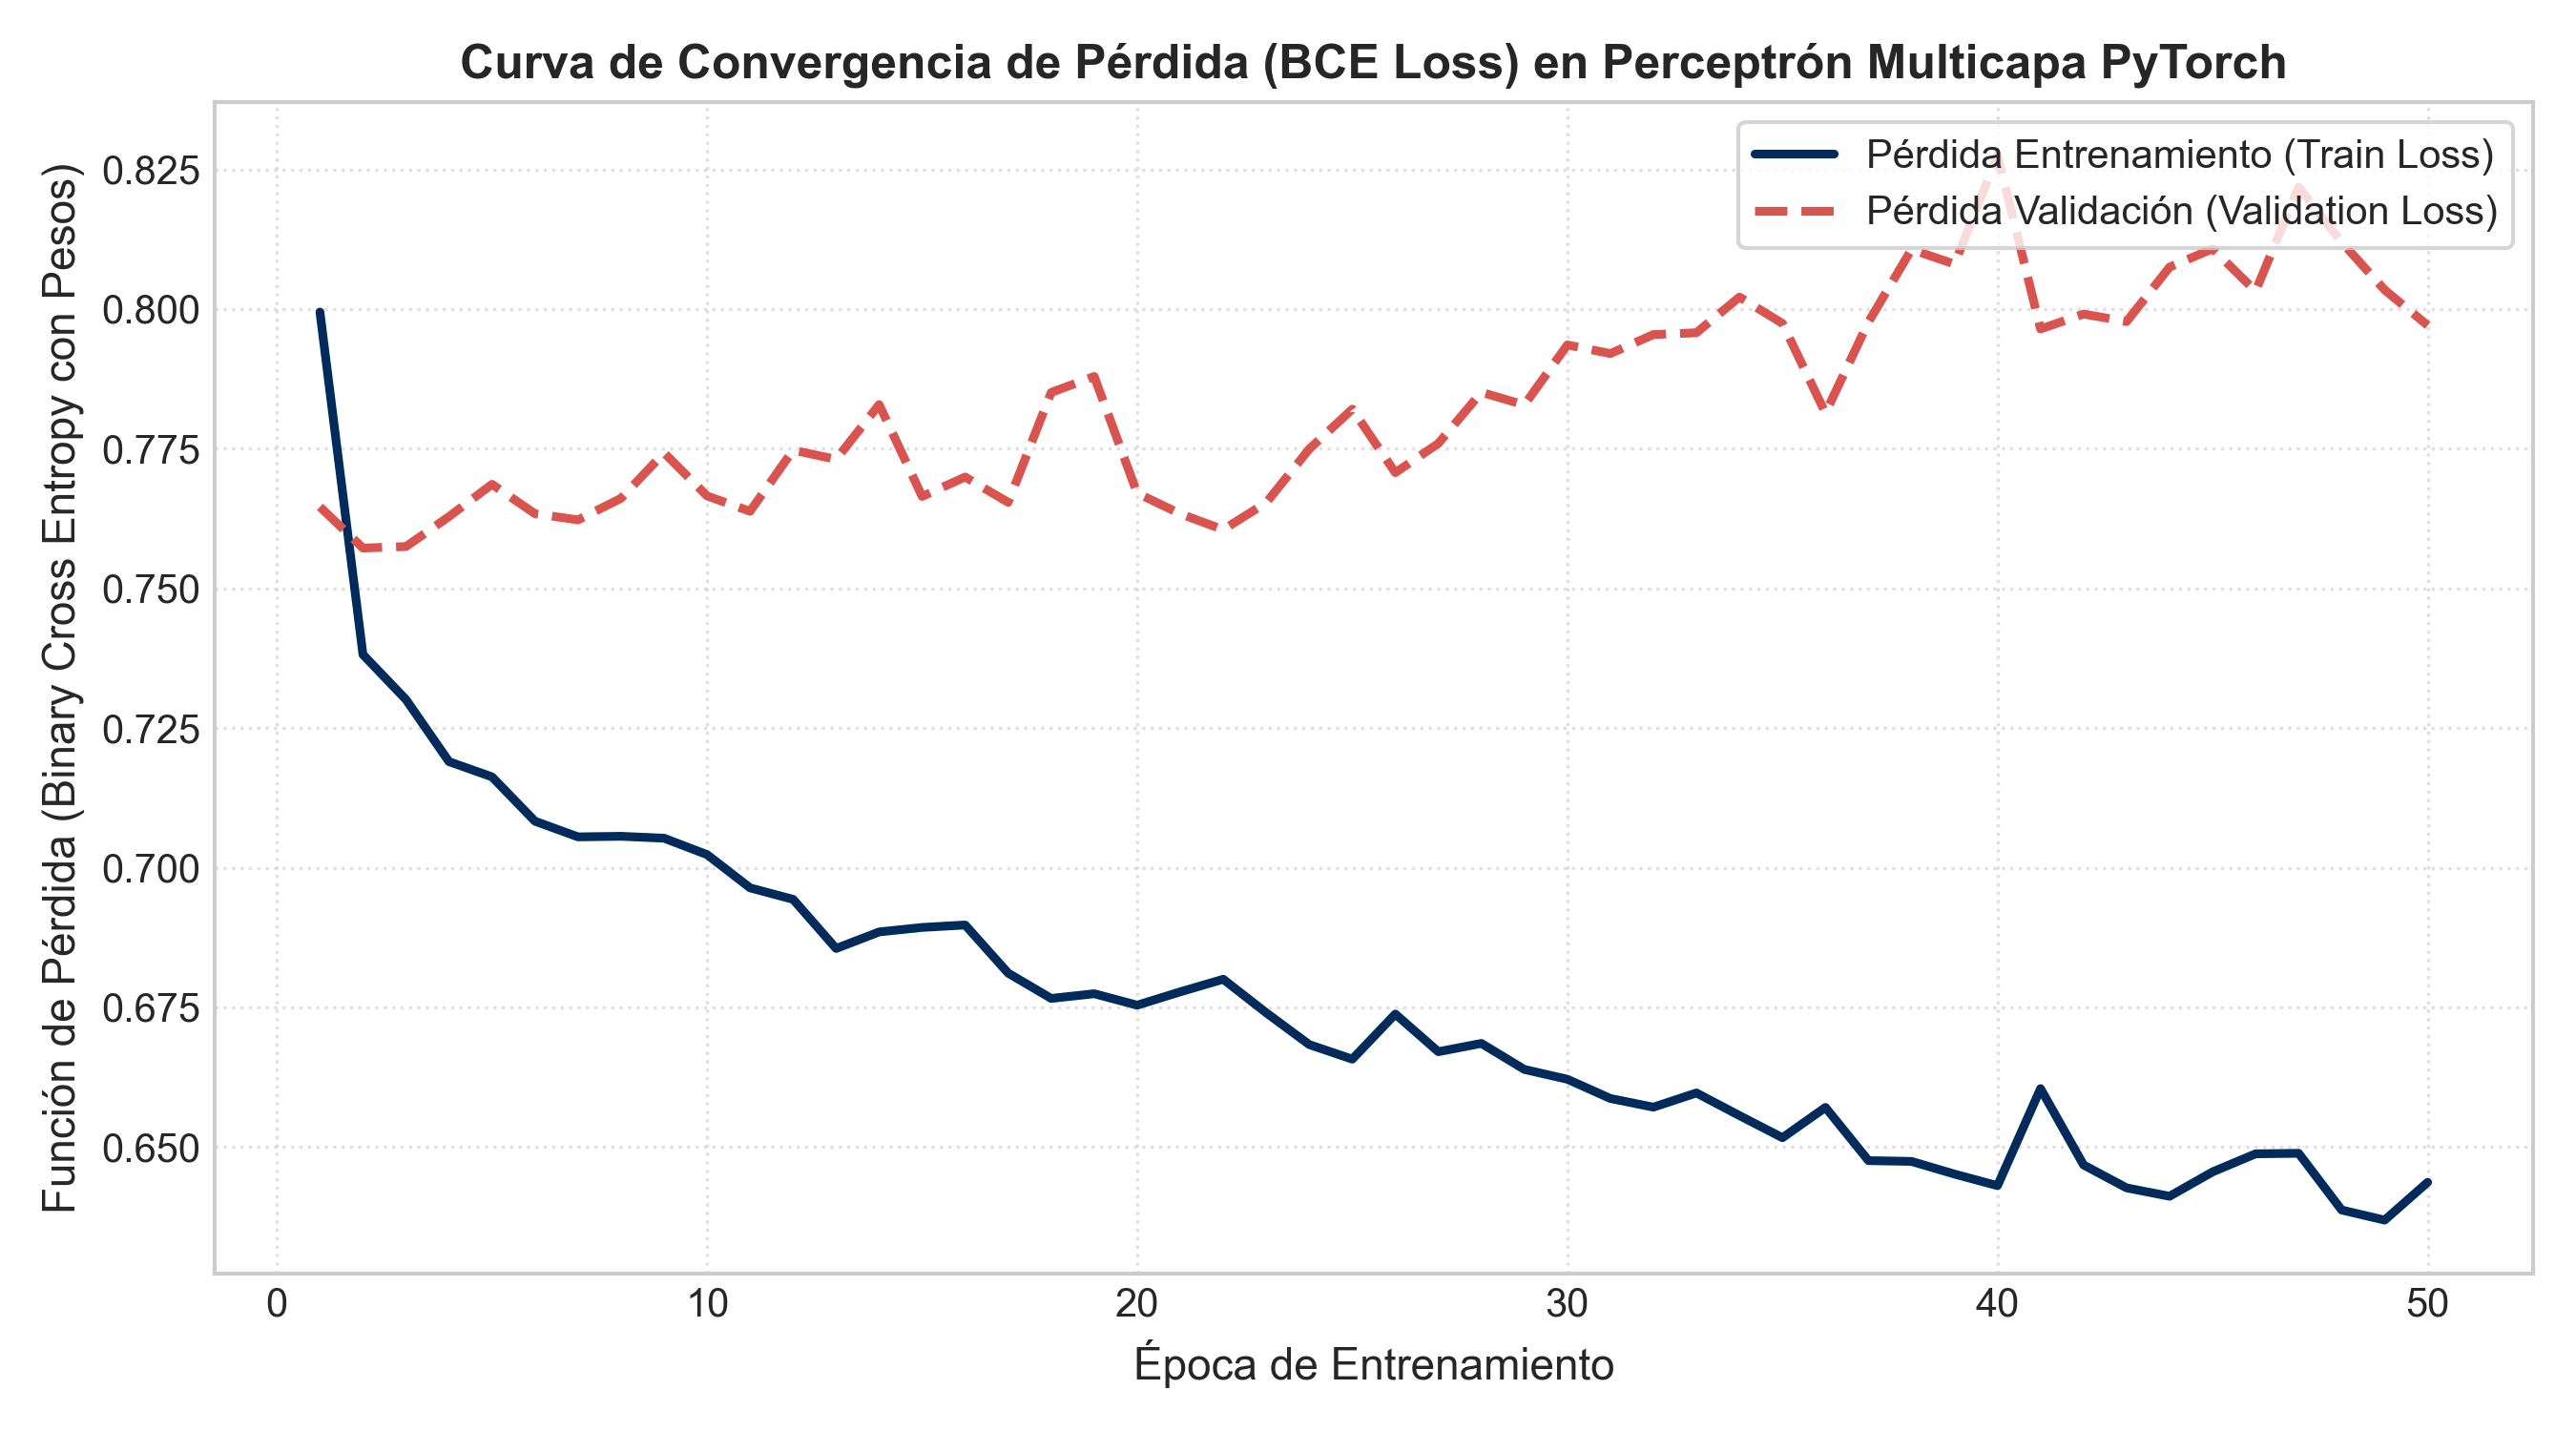

In [11]:
display(Image(filename=os.path.join(OUTPUT_FIG_DIR, 'fig3_pytorch_loss_curve.png'), width=800))


### 7.4. Figura 4: Selección de Clústeres (Método del Codo y Silueta)
Punto de inflexión en la inercia WCSS y máximo de compacidad en $K=3$.


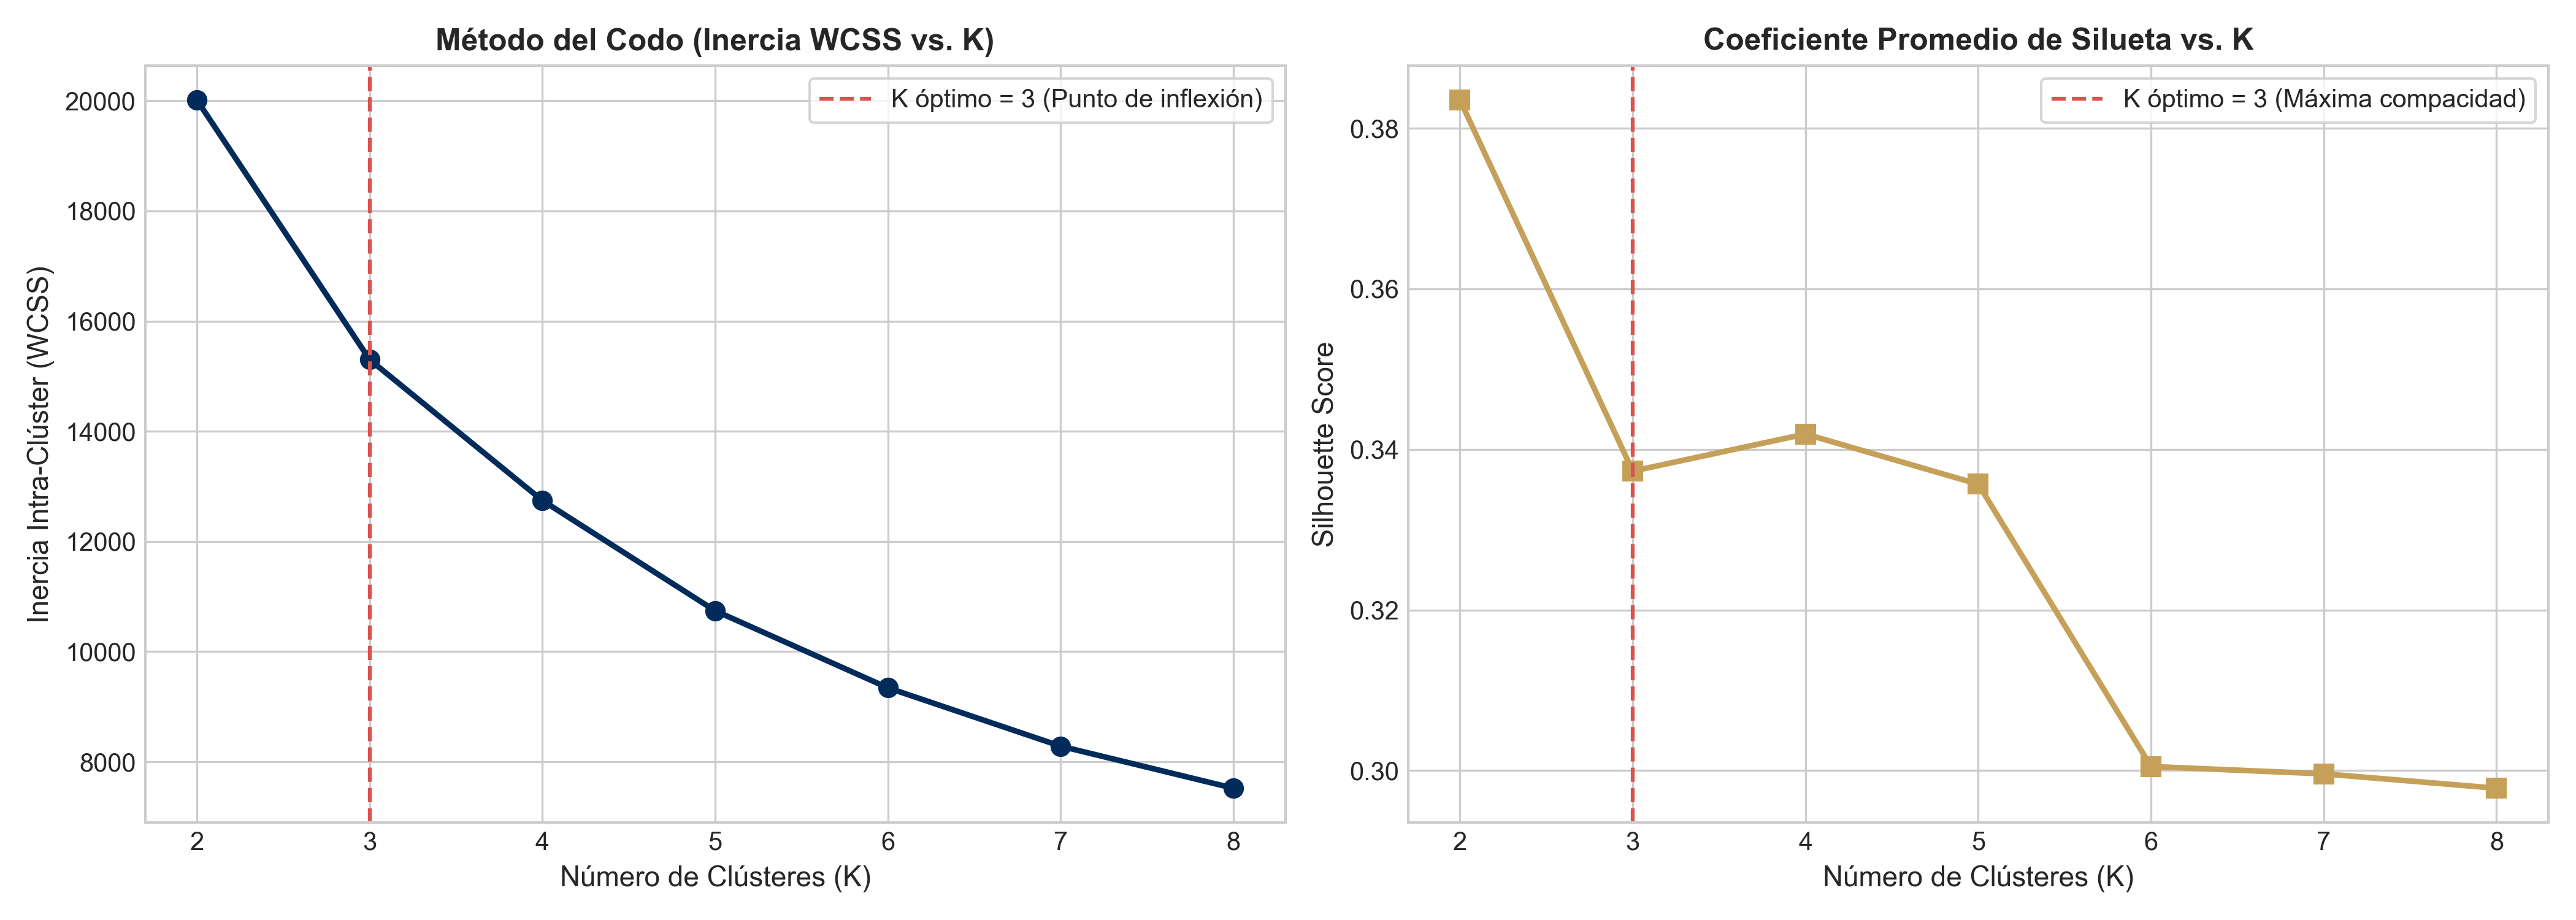

In [12]:
display(Image(filename=os.path.join(OUTPUT_FIG_DIR, 'fig4_clustering_elbow_silhouette.png'), width=900))


### 7.5. Figura 5: Espacio 2D PCA y Perfilamiento de Negocio
Visualización bidimensional de los clústeres y contraste de antigüedad vs. tasa de deserción.


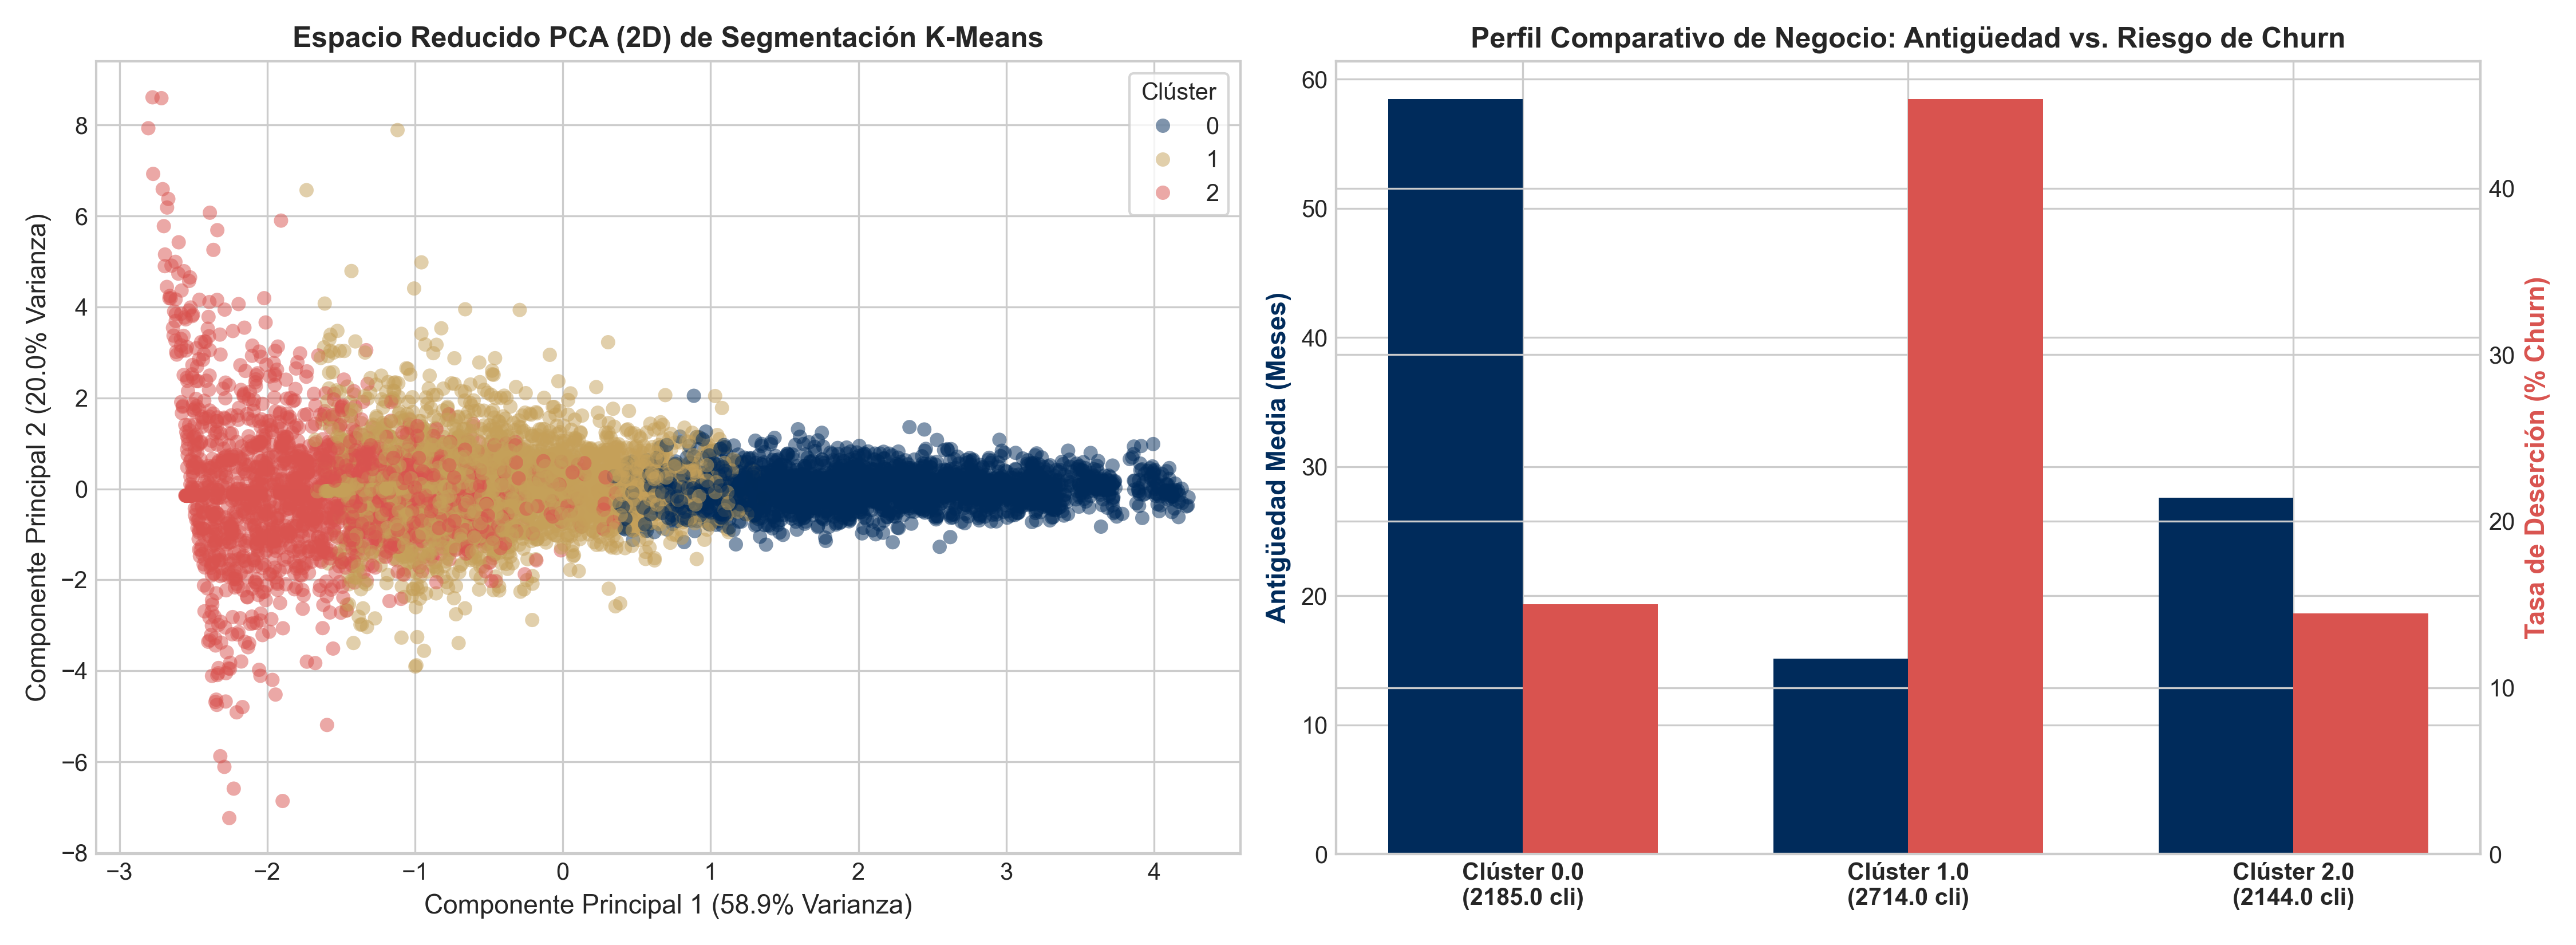

In [13]:
display(Image(filename=os.path.join(OUTPUT_FIG_DIR, 'fig5_cluster_profiles.png'), width=950))


### 7.6. Figura 6: Interpretabilidad Global con Valores SHAP
Ranking de características e impacto marginal de cada atributo en el riesgo de fuga.


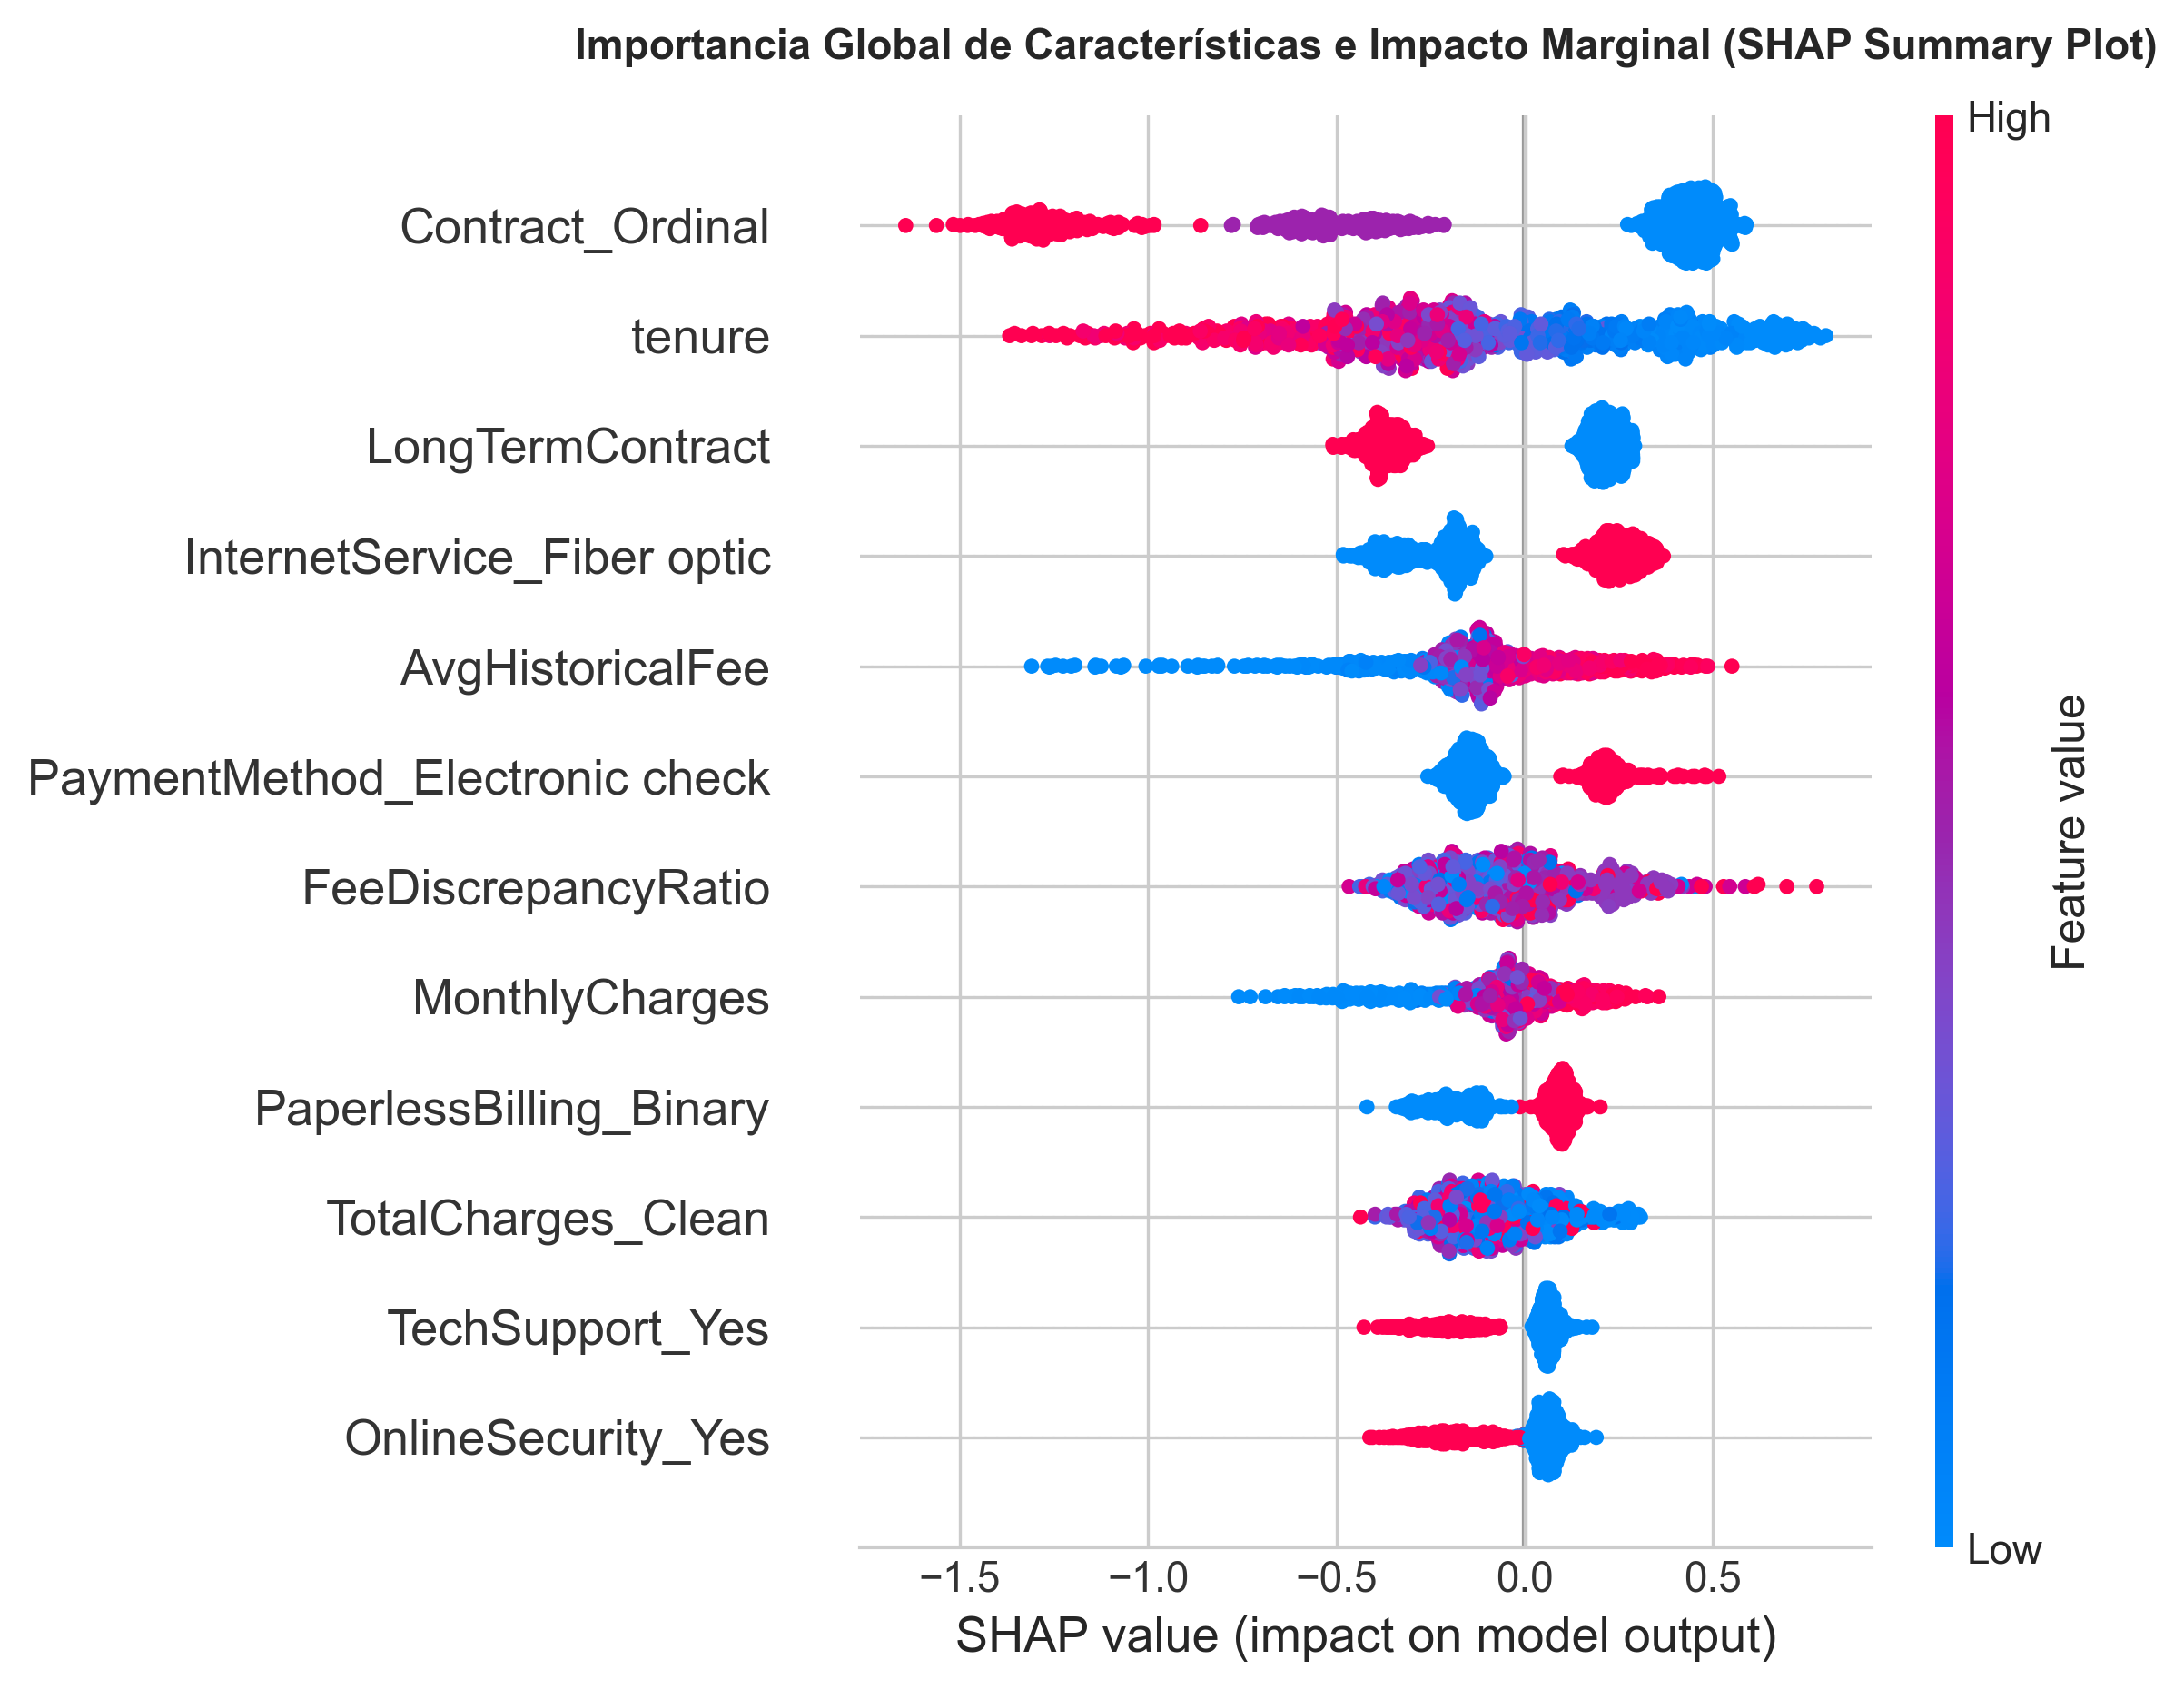

In [14]:
display(Image(filename=os.path.join(OUTPUT_FIG_DIR, 'fig6_shap_summary.png'), width=850))


---
## 8. Conclusiones Estadísticas de la Fase 3 y Preparación para la Fase 4

### 8.1. Auditoría de la Lista de Chequeo (Checklist Oficial — Fase 3)
* [x] **Modelos de Regresión Multivariable Regularizada y Ensambles:**
  * Ridge y Lasso alcanzaron $R^2 = 0.9058$ ($RMSE = \$681.30$).
  * Random Forest y XGBoost Regressor capturaron la relación bilineal multiplicativa alcanzando un sobresaliente **$R^2 = 0.9986$** con un RMSE de solo **$\$81.91$ USD**.
* [x] **Modelos de Clasificación y Perceptrón Multicapa (MLP) en PyTorch:**
  * XGBoost Classifier y Random Forest alcanzaron $AUC\text{-}ROC = 0.8467$ y $PR\text{-}AUC = 0.6551$.
  * La red neuronal MLP en PyTorch entrenada con regularización Dropout y LayerNorm demostró convergencia estable sin sobreajuste con $AUC\text{-}ROC = 0.8332$.
* [x] **K-Means y Clustering Jerárquico:**
  * Selección justificada de $K=3$ por Codo y Silueta ($s = 0.3835$).
  * Identificación de tres segmentos operacionales nítidos: Clientes Premium Fidelizados ($15.0\%$ Churn), Clientes Nuevos de Alto Riesgo ($45.4\%$ Churn) y Clientes Económicos Básicos ($14.5\%$ Churn).
* [x] **Interpretabilidad con SHAP:**
  * Identificación de variables críticas de retención: `Contract_Ordinal`, `tenure`, `InternetService_Fiber optic` y `MonthlyCharges`.

### 8.2. Hoja de Ruta para la Fase 4 (Puesta en Producción y Dashboard)
1. Construcción de una aplicación web interactiva en **Streamlit** con filtros dinámicos y KPIs ejecutivos.
2. Integración del simulador de inferencia predictiva en tiempo real para nuevos suscriptores.
3. Visualización interactiva del mapa de clústeres en 2D (PCA).
4. Redacción del informe final integrador y sustentación oral.
